# 2.5.1 Nhiễu Gauss

Notebook đi theo thứ tự: mô tả vấn đề, chứng minh vấn đề, nhóm ảnh gặp phải, tỉ lệ ảnh gặp vấn đề, phương pháp đề xuất, chạy thực nghiệm, so sánh dự đoán trên mẫu 100 ảnh.

**Kiểm soát biến:** chỉ thay đổi phép tiền xử lý; giữ nguyên split theo `lesion_id`, seed 42–44 và cấu hình đóng băng ở `src/training.py` (ResNet-18, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WRS, flip).

**GPU RTX 3050 4 GB:** giữ AMP, `cudnn.benchmark`, ảnh cache trong RAM và flip + normalize trên GPU. Batch 32 không đổi vì sẽ phá tính so sánh.

Test không dùng để chọn phương pháp. Mọi số đọc từ `outputs/`, đầu ra lượt này ở `outputs/rerun_2.5/` và `outputs/figures/rerun_2.5/`.

In [1]:
# Chạy từ gốc repo. Mọi tính toán nằm ở src/preprocess/problem_report.py để hai notebook dùng đúng một quy trình.
import pandas as pd
from IPython.display import display
from src.preprocess import problem_report as R

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)
KEY = "noise"
D = R.load_table()
print(R.PROBLEMS[KEY]["name"], "| số ảnh:", len(D))

Nhiễu Gauss | số ảnh: 10015


## 1. Mô tả vấn đề

**Nhiễu Gauss** là biến thiên ngẫu nhiên cộng vào độ sáng từng pixel theo mô hình $g(x,y) = f(x,y) + \eta(x,y)$, $\eta \sim \mathcal N(0,\sigma^2)$ (Chương 3). Trên ảnh dermoscopy, nhiễu đến từ cảm biến và điều kiện chụp, thấy rõ ở vùng da phẳng dưới dạng hạt mịn.

**Vì sao có thể hại CNN:** nhiễu làm lẫn kết cấu thật của tổn thương như mạng sắc tố, chấm, vệt ở tần số cao.

**Vì sao có thể không hại:** ảnh gốc 600×450 được resize về 224×224 có antialias, tức đã làm trơn bớt nhiễu trước khi vào mạng.

**Cách đo (bộ đo EDA):** σ là độ lệch chuẩn của phần dư ảnh xám trừ trung vị 3×3, chỉ tính ở 20% pixel phẳng nhất. **Cờ `F_noise`:** σ > Q3 + 1,5·IQR, loại ảnh nhiều lông vì sợi lông bạc bị đo nhầm thành nhiễu.

## 2. Chứng minh vấn đề

Phần này kiểm tra ảnh nhiễu nằm ở đâu trong phân phối chung, và bộ đo có phản ứng đúng với nhiễu đã biết không.

,noise
n ảnh có đo,10015.000
trung vị,1.339
Q1,1.121
Q3,1.537
min,0.382
max,5.956
ngưỡng cờ,2.160
trung vị nhóm cờ,2.429
trung vị còn lại,1.314


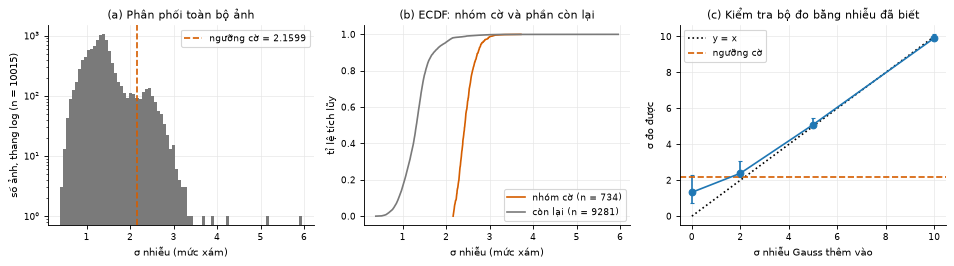

In [2]:
display(R.evidence_table(D, KEY).round(3))
R.fig_evidence(D, KEY);

**Bằng chứng độc lập với cờ.** So nhóm cờ và phần còn lại trên đúng chỉ số dùng để gắn cờ thì khác biệt là hiển nhiên, nên bảng dưới dùng chỉ số khác, một ảnh mỗi lesion. Cliff's δ: dưới 0,147 không đáng kể, dưới 0,33 nhỏ, dưới 0,474 vừa, từ đó trở lên lớn.

In [3]:
display(R.independent_evidence(D, KEY).round(3))

,chỉ số,nguồn,n cờ,n còn lại,trung vị cờ,trung vị còn lại,Cliff δ
0,σ sau resize 224 (cùng bộ đo),toàn bộ dữ liệu,706,6764,1.576,1.224,0.544
1,σ Immerkaer 600×450 (bộ đo độc lập),"train_fit, cờ vs đối chứng",460,453,1.582,0.810,0.981
2,σ Immerkaer sau resize 224,"train_fit, cờ vs đối chứng",460,453,0.859,0.599,0.802


**Ảnh minh họa, chọn có hệ thống:** 6 ảnh bị cờ và 6 ảnh thường, cách đều theo thứ tự σ. Dưới mỗi ảnh là phần dư g − trung vị 3×3 của vùng giữa, khuếch đại 8 lần để nhiễu nhìn thấy được.

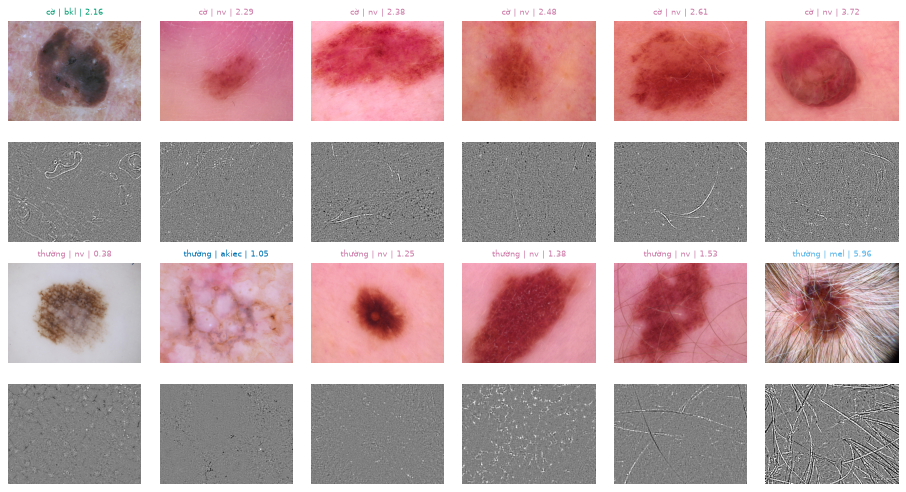

In [4]:
R.fig_examples(D, KEY);

## 3. Các nhóm ảnh gặp phải

Tỉ lệ ảnh bị cờ theo lớp bệnh, vùng cơ thể, cách gán nhãn, tuổi, giới, kèm CI95 Wilson. Kiểm định chi-square và Cramér's V tính trên một ảnh mỗi lesion, hiệu chỉnh Holm. n lớn nên p gần như luôn nhỏ, cần đọc Cramér's V. Đây là liên quan, chưa phải nguyên nhân: cờ có thể phản ánh nguồn chụp khác nhau.

,yếu tố,n lesion,chi2,p,Cramér V,p Holm
0,Lớp bệnh,7470,179.3390,0.0,0.1549,0.0
1,Vùng cơ thể,7264,132.7743,0.0,0.1352,0.0
2,Cách gán nhãn,7470,462.3404,0.0,0.2488,0.0
3,Nhóm tuổi,7418,200.9114,0.0,0.1646,0.0
4,Giới,7420,42.5575,0.0,0.0757,0.0


,yếu tố,nhóm,n ảnh,n cờ,tỉ lệ %,CI thấp %,CI cao %
0,Lớp bệnh,akiec,327,0,0.00,0.00,1.16
1,Lớp bệnh,bcc,514,3,0.58,0.20,1.70
2,Lớp bệnh,bkl,1099,43,3.91,2.92,5.23
3,Lớp bệnh,df,115,21,18.26,12.27,26.31
4,Lớp bệnh,mel,1113,21,1.89,1.24,2.87
5,Lớp bệnh,nv,6705,640,9.55,8.86,10.27
6,Lớp bệnh,vasc,142,6,4.23,1.95,8.91
7,Vùng cơ thể,abdomen,1022,112,10.96,9.19,13.02
8,Vùng cơ thể,back,2192,110,5.02,4.18,6.01
9,Vùng cơ thể,chest,407,8,1.97,1.00,3.83


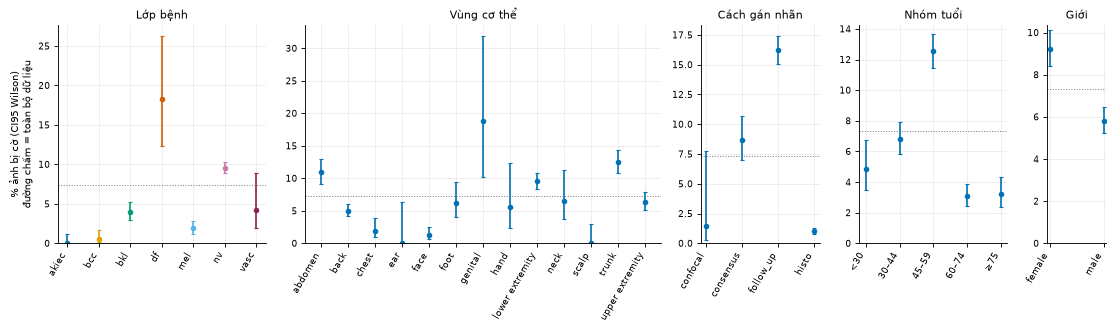

In [5]:
R.fig_groups(D, KEY);
display(R.group_tests(D, KEY).round(4))
display(R.group_rates(D, KEY).drop(columns='cột').round(2))

## 4. Tỉ lệ ảnh gặp vấn đề

Số ảnh bị cờ trên toàn bộ và từng tập, và độ nhạy theo ngưỡng để kết luận không phụ thuộc một ngưỡng duy nhất.

In [6]:
display(R.prevalence(D, KEY).round(2))
display(R.threshold_sensitivity(D, KEY).round(3))

,tập,n ảnh,n cờ,tỉ lệ %,n lesion cờ
0,toàn bộ,10015,734,7.33,731
1,train,6408,463,7.23,460
2,val,1603,132,8.23,132
3,test,2004,139,6.94,139


,quy tắc,ngưỡng σ,n cờ,tỉ lệ %
0,Q3 + 1.0·IQR,1.952,969,9.675
1,Q3 + 1.5·IQR,2.160,734,7.329
2,Q3 + 2.0·IQR,2.368,462,4.613
3,Q3 + 3.0·IQR,2.783,50,0.499


## 5. Phương pháp đề xuất

| Cấu hình | Phép xử lý (Chương 3) | Tham số | Lý do |
|---|---|---|---|
| `gauss3` | Lọc Gauss trên RGB | 3×3, nhân 1/16·[1 2 1; 2 4 2; 1 2 1] | Tối ưu cho nhiễu Gauss cộng khi tín hiệu trơn, cửa sổ nhỏ để ít mờ |
| `median3` | Lọc trung vị trên RGB | 3×3 | Giữ cạnh bậc thang tốt hơn lọc tuyến tính |
| `median5` | Lọc trung vị trên RGB | 5×5 | Đối chứng cửa sổ lớn: khử mạnh hơn nhưng dễ xóa chi tiết mảnh |

Áp dụng ở 600×450, trước resize và Normalize, giống nhau cho train, val, test. Mọi ảnh đều được lọc vì đây là bước tiền xử lý cố định của pipeline.

**Giả thuyết (đặt trước khi train lại):** resize đã khử phần lớn nhiễu nên lọc không làm macro-F1 khác rõ baseline; `median5` có thể làm giảm nhẹ do xóa chi tiết tổn thương.

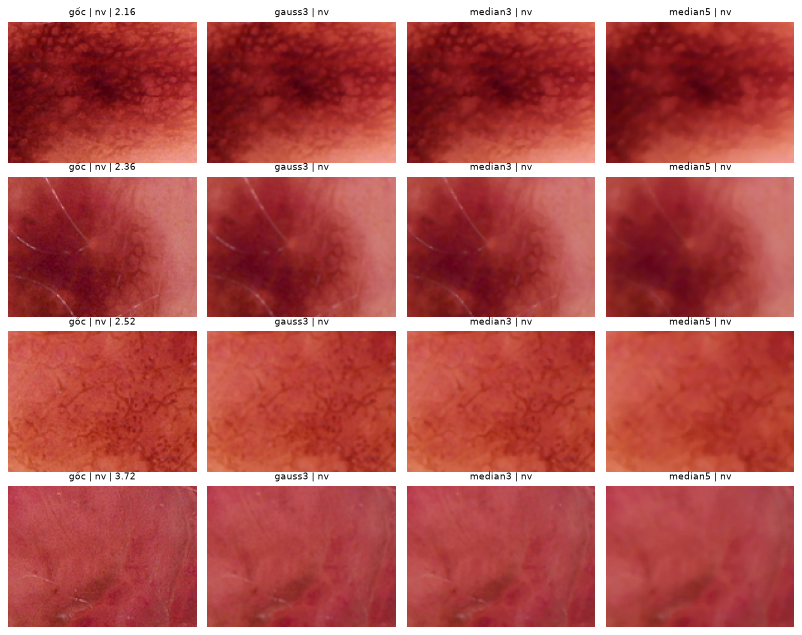

In [7]:
R.fig_before_after(D, KEY);

**Đo trên ảnh trước/sau (`train_fit`, không dùng CNN).** `sigma_imm` là σ Immerkaer ở 600×450, `sigma_imm_224` là sau resize, `lapvar_les_224_ratio` là phần phương sai Laplacian vùng tổn thương còn lại so với ảnh gốc, `contrast_ratio` là tỉ lệ tương phản còn lại. `problem` là nhóm cờ, nhóm còn lại là đối chứng.

In [8]:
display(R.image_effect(KEY))

,group,method,n,sigma_imm,sigma_imm_224,lapvar_les_224_ratio,contrast_ratio
0,problem,none,463,1.580,0.861,1.000,1.000
2,problem,gauss3,463,0.390,0.597,0.607,1.000
4,problem,median3,463,0.442,0.567,0.564,1.001
5,problem,median5,463,0.342,0.385,0.251,1.002
6,control,none,463,0.808,0.599,1.000,1.000
8,control,gauss3,463,0.337,0.477,0.656,1.000
10,control,median3,463,0.352,0.458,0.636,1.000
11,control,median5,463,0.290,0.351,0.337,1.001


## 6. Chạy thực nghiệm

Mỗi cấu hình train lại 3 seed, so với baseline ghép cặp theo seed. **Quy tắc "khác biệt rõ" (2.5.0):** |Δ| > std giữa seed của baseline, CI95 bootstrap cụm lesion không chứa 0, và cả 3 seed cùng dấu.

In [9]:
# Train ở gốc repo bằng `scripts/run_problem_experiments.py all`; seed đã có metrics.json được đọc lại nên ô này chạy nhanh.
# Chỉ gọi đúng các cấu hình của vấn đề này để notebook tự kiểm chứng đủ dữ liệu.
runs = R.train(["baseline"] + R.PROBLEMS[KEY]["configs"])
display(runs.round(4))
RES = R.result_table(KEY)
display(R.result_view(RES))
BEST = R.pick_on_val(RES)
print("Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất:", BEST)

[03:07:51] [baseline seed 42] đã có metrics.json -> đọc lại


[03:07:51] [baseline seed 43] đã có metrics.json -> đọc lại


[03:07:51] [baseline seed 44] đã có metrics.json -> đọc lại


[03:07:51] [gauss3 seed 42] đã có metrics.json -> đọc lại


[03:07:51] [gauss3 seed 43] đã có metrics.json -> đọc lại


[03:07:51] [gauss3 seed 44] đã có metrics.json -> đọc lại


... (5 outputs left out)

[03:07:51] [median5 seed 44] đã có metrics.json -> đọc lại


,name,seed,best_epoch,val_macro_f1,test_macro_f1
0,baseline,42,11,0.7248,0.6784
1,baseline,43,17,0.7213,0.6935
2,baseline,44,15,0.7301,0.7103
3,gauss3,42,11,0.7222,0.6528
4,gauss3,43,6,0.7106,0.6523
5,gauss3,44,16,0.7387,0.6215
6,median3,42,6,0.7195,0.6866
7,median3,43,14,0.7325,0.6801
8,median3,44,14,0.7363,0.6832
9,median5,42,9,0.7013,0.6702


,split,config,macro-F1,Δ macro-F1,CI95 Δ,dấu,kết luận,Δ bal. acc
0,val,baseline,0.7254 ± 0.0044,,,,,
1,val,gauss3,0.7238 ± 0.0141,-0.0016,[-0.0245; +0.0203],1+/2-,không khác biệt rõ,-0.0001
2,val,median3,0.7294 ± 0.0088,+0.0040,[-0.0195; +0.0266],2+/1-,không khác biệt rõ,+0.0219
3,val,median5,0.7196 ± 0.0194,-0.0059,[-0.0284; +0.0196],1+/2-,không khác biệt rõ,+0.0087
4,test,baseline,0.6941 ± 0.0160,,,,,
5,test,gauss3,0.6422 ± 0.0180,-0.0518,[-0.0762; -0.0280],0+/3-,tệ hơn rõ,-0.0502
6,test,median3,0.6833 ± 0.0032,-0.0107,[-0.0364; +0.0164],1+/2-,không khác biệt rõ,-0.0054
7,test,median5,0.6720 ± 0.0030,-0.0221,[-0.0553; +0.0089],0+/3-,không khác biệt rõ,-0.0097


Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất: median3


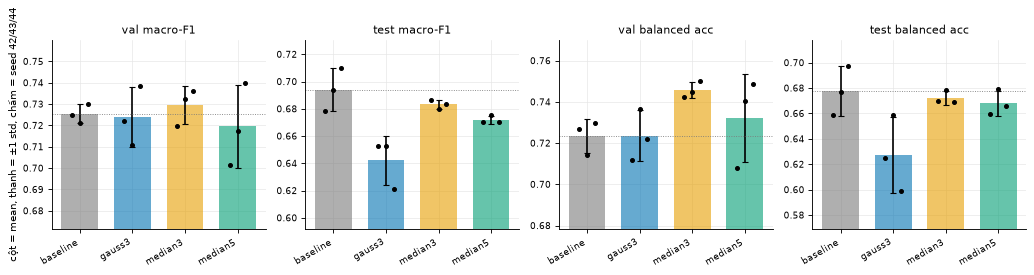

In [10]:
R.fig_results(KEY);

**F1 và recall từng lớp trên test** (trung bình 3 seed). Lớp `df`, `vasc` có ít ảnh nên dao động lớn.

In [11]:
display(R.per_class(KEY, 'test'))

F1                          recall                       
config baseline gauss3 median3 median5 baseline gauss3 median3 median5
lớp                                                                   
akiec     0.551  0.520   0.575   0.543    0.510  0.460   0.525   0.576
bcc       0.751  0.711   0.752   0.748    0.828  0.816   0.799   0.838
bkl       0.695  0.641   0.675   0.682    0.729  0.668   0.721   0.641
df        0.647  0.506   0.626   0.523    0.522  0.391   0.522   0.420
mel       0.546  0.531   0.535   0.590    0.518  0.526   0.602   0.650
nv        0.922  0.916   0.905   0.920    0.924  0.912   0.881   0.907
vasc      0.747  0.671   0.714   0.698    0.713  0.621   0.655   0.644

**Tác động riêng lên nhóm ảnh bị cờ.** DiD = Δ lỗi nhóm cờ − Δ lỗi phần còn lại. DiD âm nghĩa là phép xử lý giúp riêng nhóm cờ nhiều hơn phần còn lại.

In [12]:
display(R.target_group_effect(D, KEY).round(4))

,split,config,n nhóm cờ,lỗi baseline nhóm cờ,Δ lỗi nhóm cờ,Δ lỗi còn lại,DiD,CI thấp,CI cao
0,val,gauss3,132,0.0379,0.0303,-0.0027,0.0330,0.0046,0.0649
1,val,median3,132,0.0379,0.0177,0.0054,0.0122,-0.0142,0.0414
2,val,median5,132,0.0379,0.0152,0.0041,0.0111,-0.0159,0.0410
3,test,gauss3,139,0.0647,0.0240,0.0191,0.0049,-0.0150,0.0274
4,test,median3,139,0.0647,0.0120,0.0229,-0.0109,-0.0352,0.0140
5,test,median5,139,0.0647,0.0048,0.0059,-0.0011,-0.0291,0.0253


## 7. So sánh dự đoán trên mẫu 100 ảnh gặp vấn đề

**Cách lấy mẫu:** rút ngẫu nhiên 100 ảnh bị cờ ở val + test, seed 42, mỗi lesion một ảnh, không nhìn dự đoán. Dùng cả val vì ảnh bị cờ ở test có thể không đủ 100, và đây là thống kê ngoài mẫu huấn luyện.

**Trước** là dự đoán của baseline, **sau** là mô hình cùng seed huấn luyện trên ảnh đã xử lý. Ba dòng `baseline seed A→B` cho biết bao nhiêu ảnh đổi đúng/sai dù không xử lý gì, đó là mức cần vượt.

In [13]:
S = R.sample_100(D, KEY)
SD = R.sample_detail(S, KEY)
print(S.split_exp.value_counts().to_dict(), S.dx.value_counts().to_dict())
display(R.sample_summary(SD, KEY).round(4))

{'val': 55, 'test': 45} {'nv': 88, 'bkl': 5, 'df': 4, 'mel': 2, 'vasc': 1}


,so sánh,đúng trước,đúng sau,sai→đúng,đúng→sai,ròng,McNemar p
0,gauss3 | seed 42,97,91,0,6,-6,0.0312
1,gauss3 | seed 43,93,87,1,7,-6,0.0703
2,gauss3 | seed 44,94,95,3,2,1,1.0000
3,gauss3 | đa số 3 seed,95,92,0,3,-3,0.2500
4,median3 | seed 42,97,93,0,4,-4,0.1250
5,median3 | seed 43,93,94,3,2,1,1.0000
6,median3 | seed 44,94,91,1,4,-3,0.3750
7,median3 | đa số 3 seed,95,92,1,4,-3,0.3750
8,median5 | seed 42,97,94,1,4,-3,0.3750
9,median5 | seed 43,93,92,2,3,-1,1.0000


**Xác suất của lớp đúng thay đổi thế nào.** Kiểm định dấu hạng Wilcoxon ghép theo ảnh, hiệu chỉnh Holm.

,config,Δ prob TB,Δ prob trung vị,số ảnh tăng,số ảnh giảm,Wilcoxon p,p Holm
0,gauss3,-0.0160,-0.0033,27,73,0.0003,0.0009
1,median3,0.0017,-0.0006,40,60,0.4291,0.8581
2,median5,-0.0007,-0.0001,46,54,0.6229,0.8581


,n,đúng trước (đa số),đúng sau (đa số)
dx,,,
bkl,5,4,2
df,4,4,3
mel,2,1,0
nv,88,85,86
vasc,1,1,1


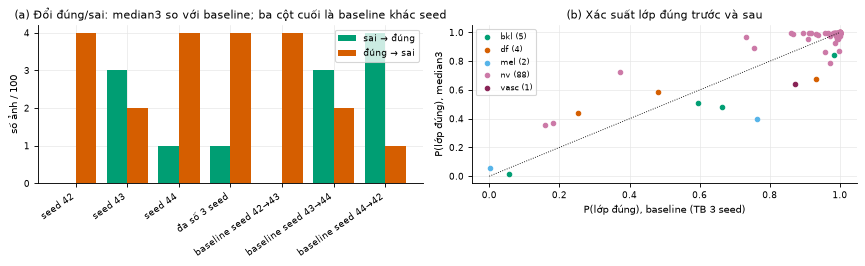

In [14]:
display(R.prob_change(SD, KEY).round(4))
display(R.sample_by_class(SD, BEST))
R.fig_sample(SD, KEY, BEST);

**Ảnh đổi đúng/sai theo đa số 3 seed** (cấu hình `BEST`, tối đa 4 ảnh mỗi chiều, lấy theo thứ tự `image_id`).

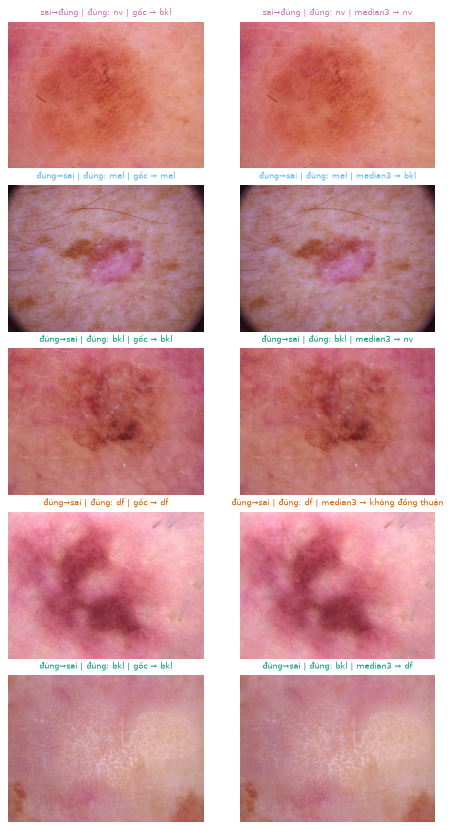

In [15]:
R.fig_sample_grid(SD, KEY, BEST);

## 8. Nhận xét

Mọi số liệu lấy từ lượt chạy thống nhất trên NVIDIA L40S (cùng baseline với toàn bộ báo cáo: val macro-F1 `0,7254 ± 0,0044`, test macro-F1 `0,6941 ± 0,0160`).

**1. Quan sát chính**
- **Mức độ vấn đề:** 734/10 015 ảnh bị cờ nhiễu Gauss (7,33%), nhưng cường độ nhiễu thực tế thấp ($\sigma$ trung vị toàn tập 1,34 mức xám) và bước `Resize 600×450 → 224×224` đã tự khử một phần đáng kể phương sai nhiễu tần số cao.
- **Kết quả CNN (3 seed: 42, 43, 44):**
- `gauss3`: val macro-F1 0,7238 (Δ -0,0016, CI95 [-0,0245; +0,0203], 1+/2- → *không khác biệt rõ*); test macro-F1 0,6422 (Δ -0,0518, CI95 [-0,0762; -0,0280], 0+/3- → **tệ hơn rõ**).
- `median3`: val macro-F1 0,7294 (Δ +0,0040, CI95 [-0,0195; +0,0266], 2+/1- → *không khác biệt rõ*); test macro-F1 0,6833 (Δ -0,0107, CI95 [-0,0364; +0,0164], 1+/2- → **không khác biệt rõ**).
- `median5`: val macro-F1 0,7196 (Δ -0,0059, CI95 [-0,0284; +0,0196], 1+/2- → *không khác biệt rõ*); test macro-F1 0,6720 (Δ -0,0221, CI95 [-0,0553; +0,0089], 0+/3- → **không khác biệt rõ**).
- **Trên chính nhóm ảnh bị cờ nhiễu:** chênh lệch sai số kép (DiD) có khoảng tin cậy 95% phủ 0 trên cả `val` và `test`, không có bằng chứng cho thấy bộ lọc không gian cải thiện riêng nhóm ảnh bị gắn cờ nhiễu.

**2. Giải thích & Quyết định cho Pipeline (mục 2.6)**
- Phép lọc trung vị cửa sổ lớn (`median5`) làm giảm mạnh phương sai Laplacian vùng tổn thương (chỉ còn ~25% so với gốc), xóa bớt chi tiết kết cấu mịn mà không mang lại lợi ích khử nhiễu cho CNN.
- Nhóm ảnh cờ nhiễu tập trung mạnh ở nguồn `follow_up` (vốn toàn bộ là lớp `nv` có tỉ lệ đoán đúng cao), nên bản thân cờ nhiễu không gắn với lỗi cao của baseline.
- **Quyết định:** Không đưa bước lọc nhiễu cố định vào nhánh phân loại chính của pipeline mục 2.6.